In [1]:
import pandas as pd
#Loading datasets
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np 
#loading the dataset
df = pd.read_csv("C:/Users/Manoh/Downloads/archive (1)/sales_data.csv.csv")
df.head
print("Data loaded Successfully!")
print(df.head())
#Missing values
print(df.isnull().sum())
#Remove duplicates
df.drop_duplicates(inplace=True)
print(f"Remaining Duplicates:{df.duplicated().sum()}")

c:\Users\Manoh\AppData\Local\Programs\Python\Python38\lib\site-packages\scipy\__init__.py:138: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.4)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion} is required for this version of "


Data loaded Successfully!
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
1       2  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
2       3  CA-2017-138688  12/06/2017  16/06/2017    Second Class    DV-13045   
3       4  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   
4       5  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City       State  \
0      Claire Gute   Consumer  United States        Henderson    Kentucky   
1      Claire Gute   Consumer  United States        Henderson    Kentucky   
2  Darrin Van Huff  Corporate  United States      Los Angeles  California   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region   

In [3]:
import pandas as pd
#Loading datasets
data = pd.read_csv("C:/Users/Manoh/Downloads/archive (1)/sales_data.csv.csv")
df.head
#Statistical measures
column='Sales'
data[column]=data[column].fillna(data[column].mean())
mean = data[column].mean()
median = data[column].median()
std_dev = data[column].std()
variance = data[column].var()
print(f"Mean of {column}: {mean}")
print(f"Median of {column}: {median}")
print(f"Standard Deviation of {column}: {std_dev}")
print(f"Variance of {column}: {variance}")
#Correlation 
numeric_data = data.select_dtypes(include=['number'])
correlation_matrix=numeric_data.corr()
print("Correlation Matrix")
print(correlation_matrix)

Mean of Sales: 230.7690594591837
Median of Sales: 54.489999999999995
Standard Deviation of Sales: 626.6518748388042
Variance of Sales: 392692.5722389884
Correlation Matrix
               Row ID  Postal Code     Sales
Row ID       1.000000     0.013645  0.001151
Postal Code  0.013645     1.000000 -0.024067
Sales        0.001151    -0.024067  1.000000


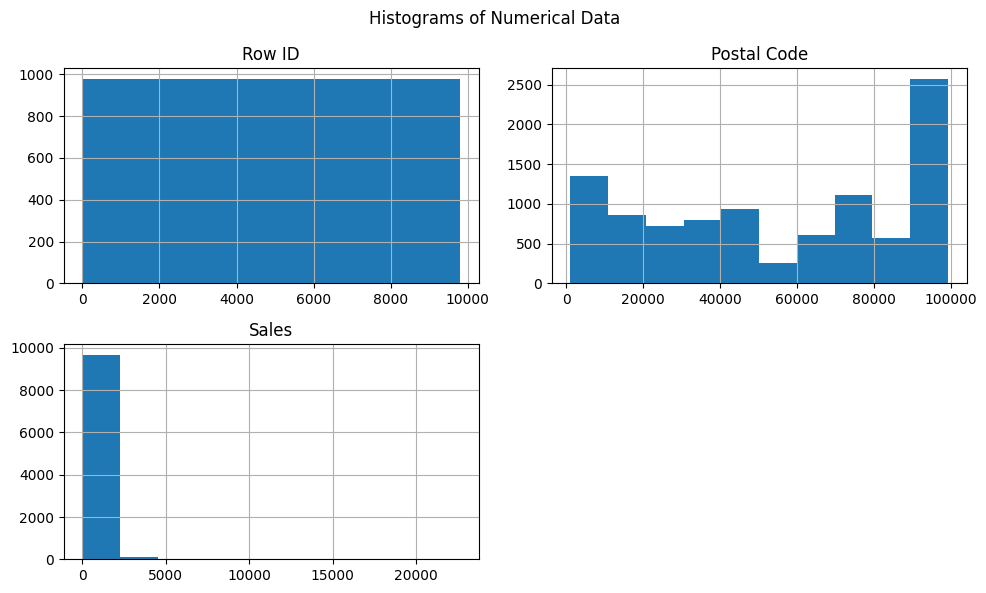

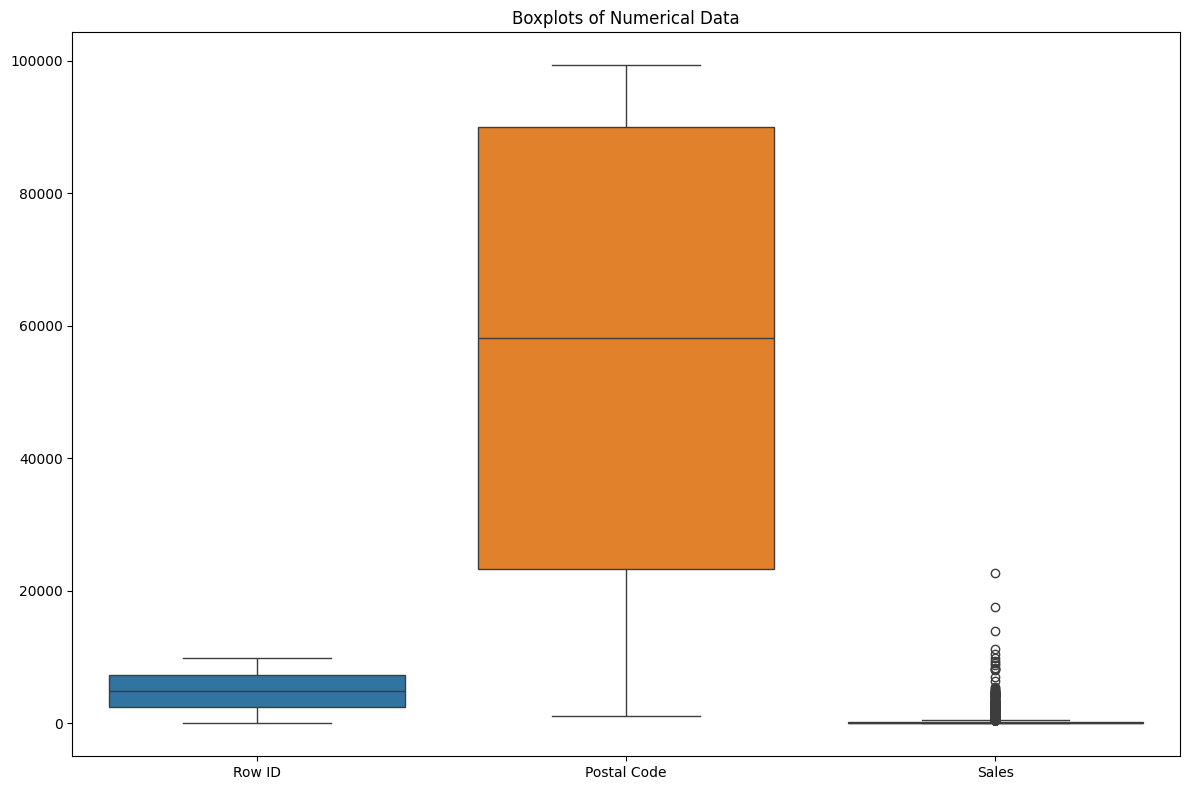

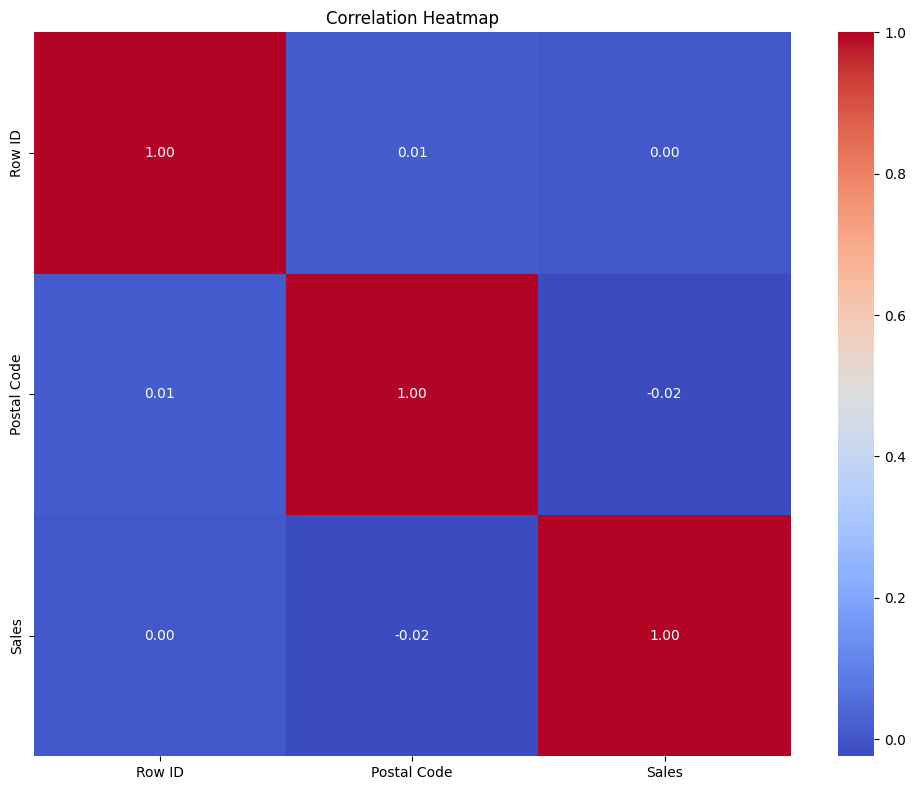

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


data = pd.read_csv("C:/Users/Manoh/Downloads/archive (1)/sales_data.csv.csv")
df.head
# 1. Histograms
data.hist(figsize=(10, 6))
plt.suptitle('Histograms of Numerical Data')
plt.tight_layout()
plt.show()
 
# 2. Boxplots
plt.figure(figsize=(12, 8))
sns.boxplot(data=data.select_dtypes(include=['number']))  # Only use numerical columns
plt.title('Boxplots of Numerical Data')
plt.tight_layout()
plt.show()
# 3. Heatmap
numeric_data = data.select_dtypes(include=['number'])
correlation_matrix = numeric_data.corr()  # Calculate the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales'],
      dtype='object')
Column 'Profit' does not exist in the dataset.


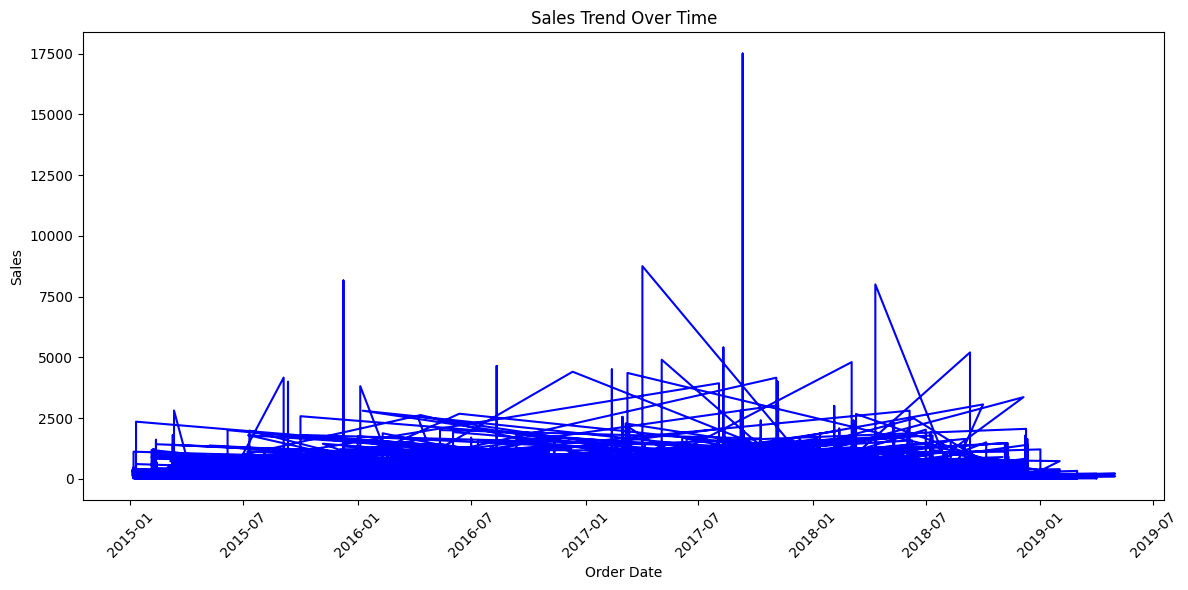

Required columns for scatter plot do not exist.


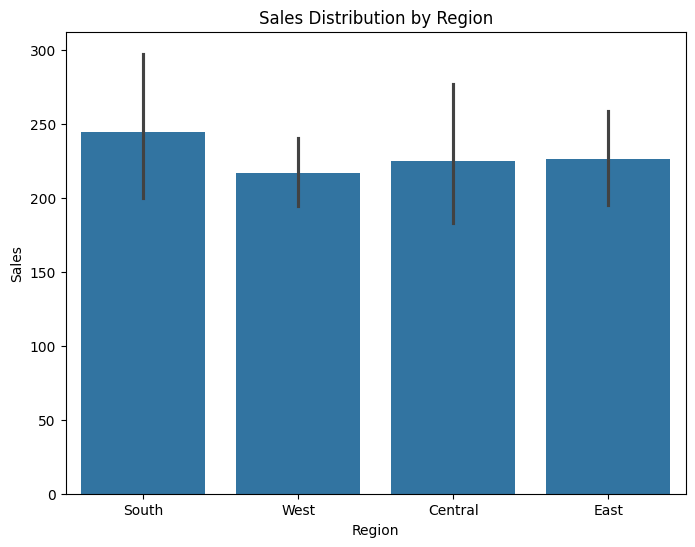

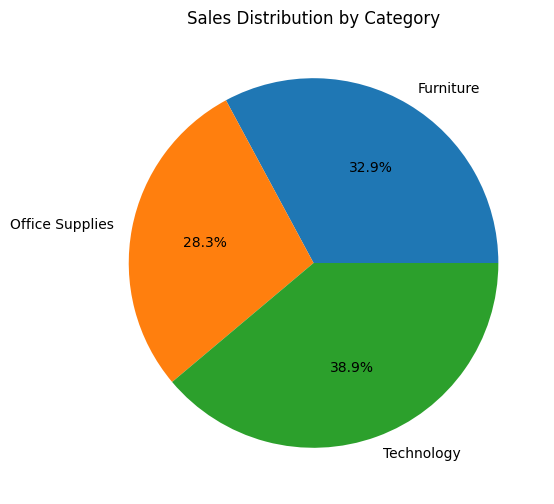

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Data
data = pd.read_csv("C:/Users/Manoh/Downloads/archive (1)/sales_data.csv.csv")

# Check column names
print(data.columns)

# Remove duplicates
data = data.drop_duplicates()

# Handle missing values
if 'Sales' in data.columns:
    data['Sales'].fillna(data['Sales'].mean(), inplace=True)
else:
    print("Column 'Sales' does not exist in the dataset.")

if 'Profit' in data.columns:
    data['Profit'].fillna(data['Profit'].mean(), inplace=True)
else:
    print("Column 'Profit' does not exist in the dataset.")

# Convert 'Ship Date' to datetime and handle missing/invalid dates
data['Ship Date'] = pd.to_datetime(data['Ship Date'], errors='coerce')
data.dropna(subset=['Ship Date'], inplace=True)

# Ensure 'Sales' is numeric
data['Sales'] = pd.to_numeric(data['Sales'], errors='coerce')

# Plot time series graph for Sales over time
plt.figure(figsize=(12, 6))
plt.plot(data['Ship Date'].to_numpy(), data['Sales'].to_numpy(), color='blue')
plt.title('Sales Trend Over Time')
plt.xlabel('Order Date')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Scatter plot for Profit vs Discount
if 'Discount' in data.columns and 'Profit' in data.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(x='Discount', y='Profit', data=data)
    plt.title('Profit vs Discount')
    plt.xlabel('Discount')
    plt.ylabel('Profit')
    plt.show()
else:
    print("Required columns for scatter plot do not exist.")

# Bar plot for sales distribution by Region
if 'Region' in data.columns and 'Sales' in data.columns:
    plt.figure(figsize=(8, 6))
    sns.barplot(x='Region', y='Sales', data=data)
    plt.title('Sales Distribution by Region')
    plt.xlabel('Region')
    plt.ylabel('Sales')
    plt.show()
else:
    print("Required columns for bar plot do not exist.")

# Pie chart for sales distribution by Category
if 'Category' in data.columns and 'Sales' in data.columns:
    category_sales = data.groupby('Category')['Sales'].sum()
    category_sales.plot(kind='pie', autopct='%1.1f%%', figsize=(8, 6))
    plt.title('Sales Distribution by Category')
    plt.ylabel('')
    plt.show()
else:
    print("Required columns for pie chart do not exist.")